# Домашняя работа № 2: NYC Taxi

> Решение задачи **многоклассовой классификации**: предсказание диапазона длительности поездки на такси в Нью-Йорке с помощью логистической классификации и KNN.

В `train.csv` сохраняются следующие поля исходной записи:

| Поле | Описание |
|---|---|
| `trip_id` | Идентификатор поездки для сопоставления строк и предсказаний |
| `vendor_id` | Код провайдера поездки |
| `pickup_datetime` | Время начала поездки |
| `dropoff_datetime` | Время завершения поездки |
| `passenger_count` | Число пассажиров |
| `pickup_longitude`, `pickup_latitude` | Координаты посадки |
| `dropoff_longitude`, `dropoff_latitude` | Координаты назначения |
| `store_and_fwd_flag` | Признак передачи записи из памяти устройства после отсутствия связи |
| `trip_duration` | Продолжительность поездки в секундах |
| `target` | Класс продолжительности поездки (0-3) |

Сущсетвует три файла:

| Файл | Объекты | Что доступно | Назначение |
|---|---:|---|---|
| `train.csv` | 80 000 | Исторические записи с `target` | Исследование, обучение, кросс-валидация |
| `test-public.csv` | 15 000 | Тестовые данные с `target` | Открытая проверка моделей |
| `test-private.csv` | 25 000 | Тестовые данные без `target` | Итоговые предсказания |

Описание таргета:
| Класс | Продолжительность поездки |
|---|---|
| `0` | Меньше 5 минут |
| `1` | От 5 до 15 минут |
| `2` | От 15 до 30 минут |
| `3` | 30 минут и более |

## 0. Настройка окружения и загрузка файлов

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import make_scorer, ConfusionMatrixDisplay, f1_score, accuracy_score, recall_score, precision_score, roc_curve, precision_recall_curve, classification_report
from scipy.stats import randint, uniform
from sklearn.base import clone

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

In [2]:
from pathlib import Path
import os

def load_student_data(data_dir):
    """Прочитать три CSV без изменения их содержимого."""
    data_dir = Path(data_dir)
    train = pd.read_csv(data_dir / "train.csv")
    public = pd.read_csv(data_dir / "test-public.csv")
    private = pd.read_csv(data_dir / "test-private.csv")
    return train, public, private


DATA_DIR = Path(os.environ.get("HW02_DATA_DIR", "data"))  # Укажите свою папку.

train = public = private = None
if any((DATA_DIR / name).exists() for name in
       ["train.csv", "test-public.csv", "test-private.csv"]):
    train, public, private = load_student_data(DATA_DIR)
else:
    print("CSV пока не найдены. После получения файлов укажите их папку в DATA_DIR.")

## 1. EDA + Feature engineering

### 1.1 Общие наблюдения

In [3]:
train.head(3)

,trip_id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,target
0,trip_0744631,1,2016-06-03 20:55:43,2016-06-03 21:00:30,1,-73.977524,40.779175,-73.988045,40.764778,N,287,0
1,trip_0004949,2,2016-01-01 15:48:15,2016-01-01 16:15:51,5,-73.863808,40.769009,-73.991623,40.746590,N,1656,2
2,trip_0300063,1,2016-04-08 15:21:46,2016-04-08 15:28:02,1,-73.937584,40.812889,-73.947403,40.805370,N,376,1


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   trip_id             80000 non-null  object 
 1   vendor_id           80000 non-null  int64  
 2   pickup_datetime     80000 non-null  object 
 3   dropoff_datetime    80000 non-null  object 
 4   passenger_count     80000 non-null  int64  
 5   pickup_longitude    80000 non-null  float64
 6   pickup_latitude     80000 non-null  float64
 7   dropoff_longitude   80000 non-null  float64
 8   dropoff_latitude    80000 non-null  float64
 9   store_and_fwd_flag  80000 non-null  object 
 10  trip_duration       80000 non-null  int64  
 11  target              80000 non-null  int64  
dtypes: float64(4), int64(4), object(4)
memory usage: 7.3+ MB


Идеи на будующее:
1. Есть даты:
  - преобразовать в формат дат во всех трех файлах
  - спарсить час, день недели, месяц год с даты
  - сделать циклические признаки из часа

2. Геоданные:
  - вычислить растояние между пунктом отправления и назначения
  - выделить кластеры по растоянию поездок?
  - сделать карту поездок?


In [5]:
# базовые статистики
train.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,target
count,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000
mean,1.532850,1.664087,-73.973243,40.750923,-73.973322,40.751830,952.990300,1.263187
std,0.498923,1.314790,0.038884,0.028487,0.036282,0.032584,3189.954096,0.807219
min,1.000000,0.000000,-74.455559,40.551376,-74.455559,40.543148,1.000000,0.000000
25%,1.000000,1.000000,-73.991800,40.737369,-73.991325,40.735869,396.000000,1.000000
50%,2.000000,1.000000,-73.981674,40.754147,-73.979744,40.754511,660.000000,1.000000
75%,2.000000,2.000000,-73.967224,40.768505,-73.963058,40.769829,1080.000000,2.000000
max,2.000000,7.000000,-73.195259,41.292198,-73.195259,41.318459,86362.000000,3.000000


In [6]:
# пропуски
train.isna().sum()

,0
trip_id,0
vendor_id,0
pickup_datetime,0
dropoff_datetime,0
passenger_count,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
store_and_fwd_flag,0


In [7]:
# посмотрим краевые значения длительности поездки, чтобы выявить возможные выбросы
print(f'Максимальная длительность поездки: {round(train['trip_duration'].max()/3600, 4)} ч.')
print(f'Минимальная длительность поездки: {round(train['trip_duration'].min()/3600, 4)} ч.')

Максимальная длительность поездки: 23.9894 ч.
Минимальная длительность поездки: 0.0003 ч.


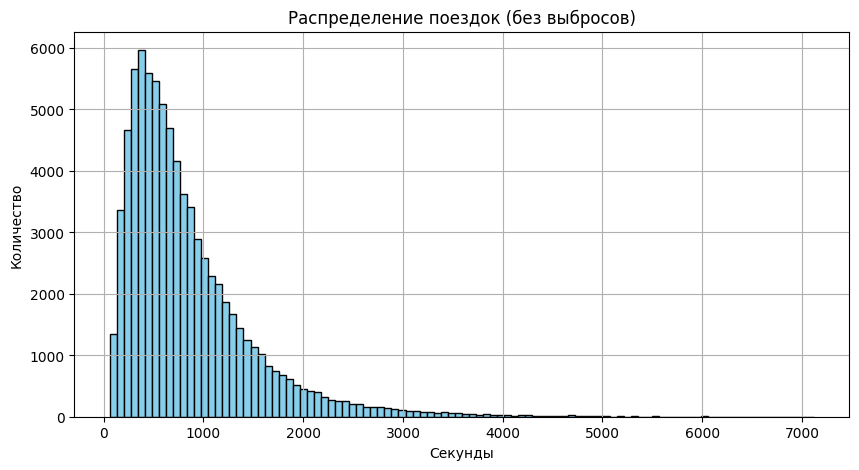

In [8]:
# т.к вышли странные значения, ограничим длины поездки

# 1. Берем только поездки от 1 минуты до 2 часов
train = train[(train['trip_duration'] >= 60) & (train['trip_duration'] <= 7200)]

# 2. Строим график распределения длины поездки
train['trip_duration'].hist(bins=100, figsize=(10, 5), color='skyblue', edgecolor='black')

plt.title('Распределение поездок (без выбросов)')
plt.xlabel('Секунды')
plt.ylabel('Количество')
plt.show()

In [9]:
# теперь убираем trip_duration из train, т.к. это прямая утечка таргета
train = train.drop(columns=['trip_duration'])

### 1.2 Работа с датами и геоданными

In [10]:
# данные с датами (тут не считаем продолжительность поездки и тд, так как в тесте не будет времени прибытия)
# + работа с геоданными, считаем растояние от точки посадки до точки высадки (через Haversine)
def add_time_features(df: pd.DataFrame, col: str, prefix: str) -> pd.DataFrame:
    """Циклические признаки из одной datetime-колонки."""
    dt = df[col]

    hour      = dt.dt.hour
    dow       = dt.dt.dayofweek          # 0=Mon .. 6=Sun
    month     = dt.dt.month

    df[f'{prefix}_hour']       = hour
    df[f'{prefix}_dayofweek']  = dow
    df[f'{prefix}_month']      = month
    df[f'{prefix}_is_weekend'] = (dow >= 5).astype('int8')

    # циклические
    df[f'{prefix}_hour_sin'] = np.sin(2*np.pi * hour / 24)
    df[f'{prefix}_hour_cos'] = np.cos(2*np.pi * hour / 24)
    df[f'{prefix}_dow_sin']  = np.sin(2*np.pi * dow / 7)
    df[f'{prefix}_dow_cos']  = np.cos(2*np.pi * dow / 7)
    df[f'{prefix}_month_sin']= np.sin(2*np.pi * (month - 1) / 12)
    df[f'{prefix}_month_cos']= np.cos(2*np.pi * (month - 1) / 12)

    # "Час недели", зависимость между часом и днем недели
    how = dow * 24 + hour
    df[f'{prefix}_how_sin'] = np.sin(2*np.pi * how / 168)
    df[f'{prefix}_how_cos'] = np.cos(2*np.pi * how / 168)

    return df

def haversine_km(lat1, lon1, lat2, lon2):
    """Расстояние по большому кругу в километрах. Работает с pandas Series."""
    R = 6371.0  # радиус Земли, км
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))


def process_data(df: pd.DataFrame,
                 start_col: str = 'pickup_datetime',
                 end_col: str   = 'dropoff_datetime',
                 plat='pickup_latitude', plon='pickup_longitude',
                 dlat='dropoff_latitude', dlon='dropoff_longitude') -> pd.DataFrame:
    """ Обработка дат и геоданных"""
    df = df.copy()

    # парсинг + даты в нужный тип
    df[start_col] = pd.to_datetime(df[start_col], errors='coerce')  # начало поездки

    # общие признаки
    df['year'] = df[start_col].dt.year
    df['day']  = df[start_col].dt.day

    df = add_time_features(df, start_col, 'start')

    df['distance_km'] = haversine_km(df[plat], df[plon], df[dlat], df[dlon])

    return df

train  = process_data(train)
public  = process_data(public)
private = process_data(private)

In [11]:
# Для этого нужна версия Plotly >= 5.24
import plotly.express as px
import plotly

sample = train.sample(5000, random_state=0)

fig = px.scatter_map(
    sample,
    lat='pickup_latitude',
    lon='pickup_longitude',
    color='target',
    zoom=10,
    height=700,
    map_style='open-street-map'
)
fig.show()

Видно, что поездки сконцентрированы в основном в центре города, при этом есть небольшие скопления точек у аэропортов. Такси в аэропорт (или из) можно отнести к особой категории, поэтому создадим новый признак, оборзначающий произошло ли начало/конец поездки в аэропорту.

In [12]:
def add_airport_features(df: pd.DataFrame, lat_col: str, lon_col: str, prefix: str) -> pd.DataFrame:
    """
    Добавляет бинарные фичи: попала ли точка в радиус 2 км от аэропортов JFK, LGA, EWR.
    prefix: 'pickup' или 'dropoff' (для названий колонок).
    """
    # Координаты аэропортов
    JFK_LAT, JFK_LON = 40.6413, -73.7781
    LGA_LAT, LGA_LON = 40.7769, -73.8740
    EWR_LAT, EWR_LON = 40.6895, -74.1745

    # Считаем расстояние от каждой точки до каждого аэропорта
    dist_jfk = haversine_km(df[lat_col], df[lon_col], JFK_LAT, JFK_LON)
    dist_lga = haversine_km(df[lat_col], df[lon_col], LGA_LAT, LGA_LON)
    dist_ewr = haversine_km(df[lat_col], df[lon_col], EWR_LAT, EWR_LON)

    # Радиус 2 км (если NaN, то результат сравнения будет False -> 0)
    df[f'{prefix}_is_jfk'] = (dist_jfk <= 2).astype('int8')
    df[f'{prefix}_is_lga'] = (dist_lga <= 2).astype('int8')
    df[f'{prefix}_is_ewr'] = (dist_ewr <= 2).astype('int8')

    # Общая фича: это аэропорт (любой из трех)
    df[f'{prefix}_is_airport'] = (
        (dist_jfk <= 2) | (dist_lga <= 2) | (dist_ewr <= 2)
    ).astype('int8')

    return df

train = add_airport_features(train, 'pickup_latitude', 'pickup_longitude', 'pickup')
train = add_airport_features(train, 'dropoff_latitude', 'dropoff_longitude', 'dropoff')

public = add_airport_features(public, 'pickup_latitude', 'pickup_longitude', 'pickup')
public = add_airport_features(public, 'dropoff_latitude', 'dropoff_longitude', 'dropoff')

private = add_airport_features(private, 'pickup_latitude', 'pickup_longitude', 'pickup')
private = add_airport_features(private, 'dropoff_latitude', 'dropoff_longitude', 'dropoff')

In [13]:
# Проверим новые признаки
# 1. Доля поездок в аэропортах
print("Доля стартов в аэропортах:", train['pickup_is_airport'].mean())
print("Доля финишей в аэропортах:", train['dropoff_is_airport'].mean())

# 2. Посмотрим на карте, где именно сработали флаги
import plotly.express as px

airport_trips = train[train['pickup_is_airport'] == 1].sample(min(5000, len(train[train['pickup_is_airport'] == 1])), random_state=42)

fig = px.scatter_mapbox(
    airport_trips,
    lat='pickup_latitude',
    lon='pickup_longitude',
    color='pickup_is_jfk',
    zoom=9,
    height=600,
    mapbox_style='open-street-map', # <--- ВОТ ЭТА СТРОКА
    title='Точки старта в аэропортах'
)
fig.show()

Доля стартов в аэропортах: 0.04775514315211644
Доля финишей в аэропортах: 0.021894593709868303


### 1.3 Целевая переменная

<Axes: >

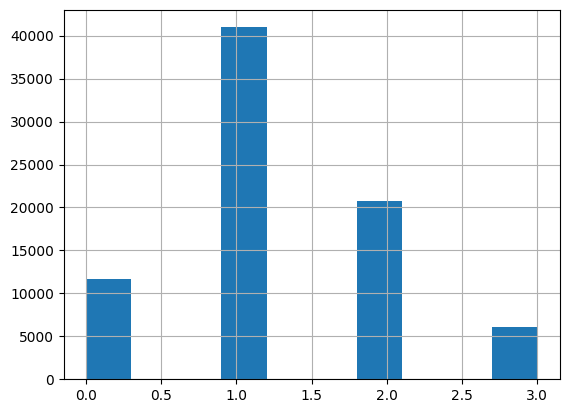

In [14]:
# распеделение
train['target'].hist(bins=10)

Виден дисбаланс классов: категория 1 занимает гораздо большее количество наблюдений, а категория 3 является наименьшей.  
Можно сделать вывод, что лучше не смотреть на метрику accuracy и делать макроусреднение, а не микро.

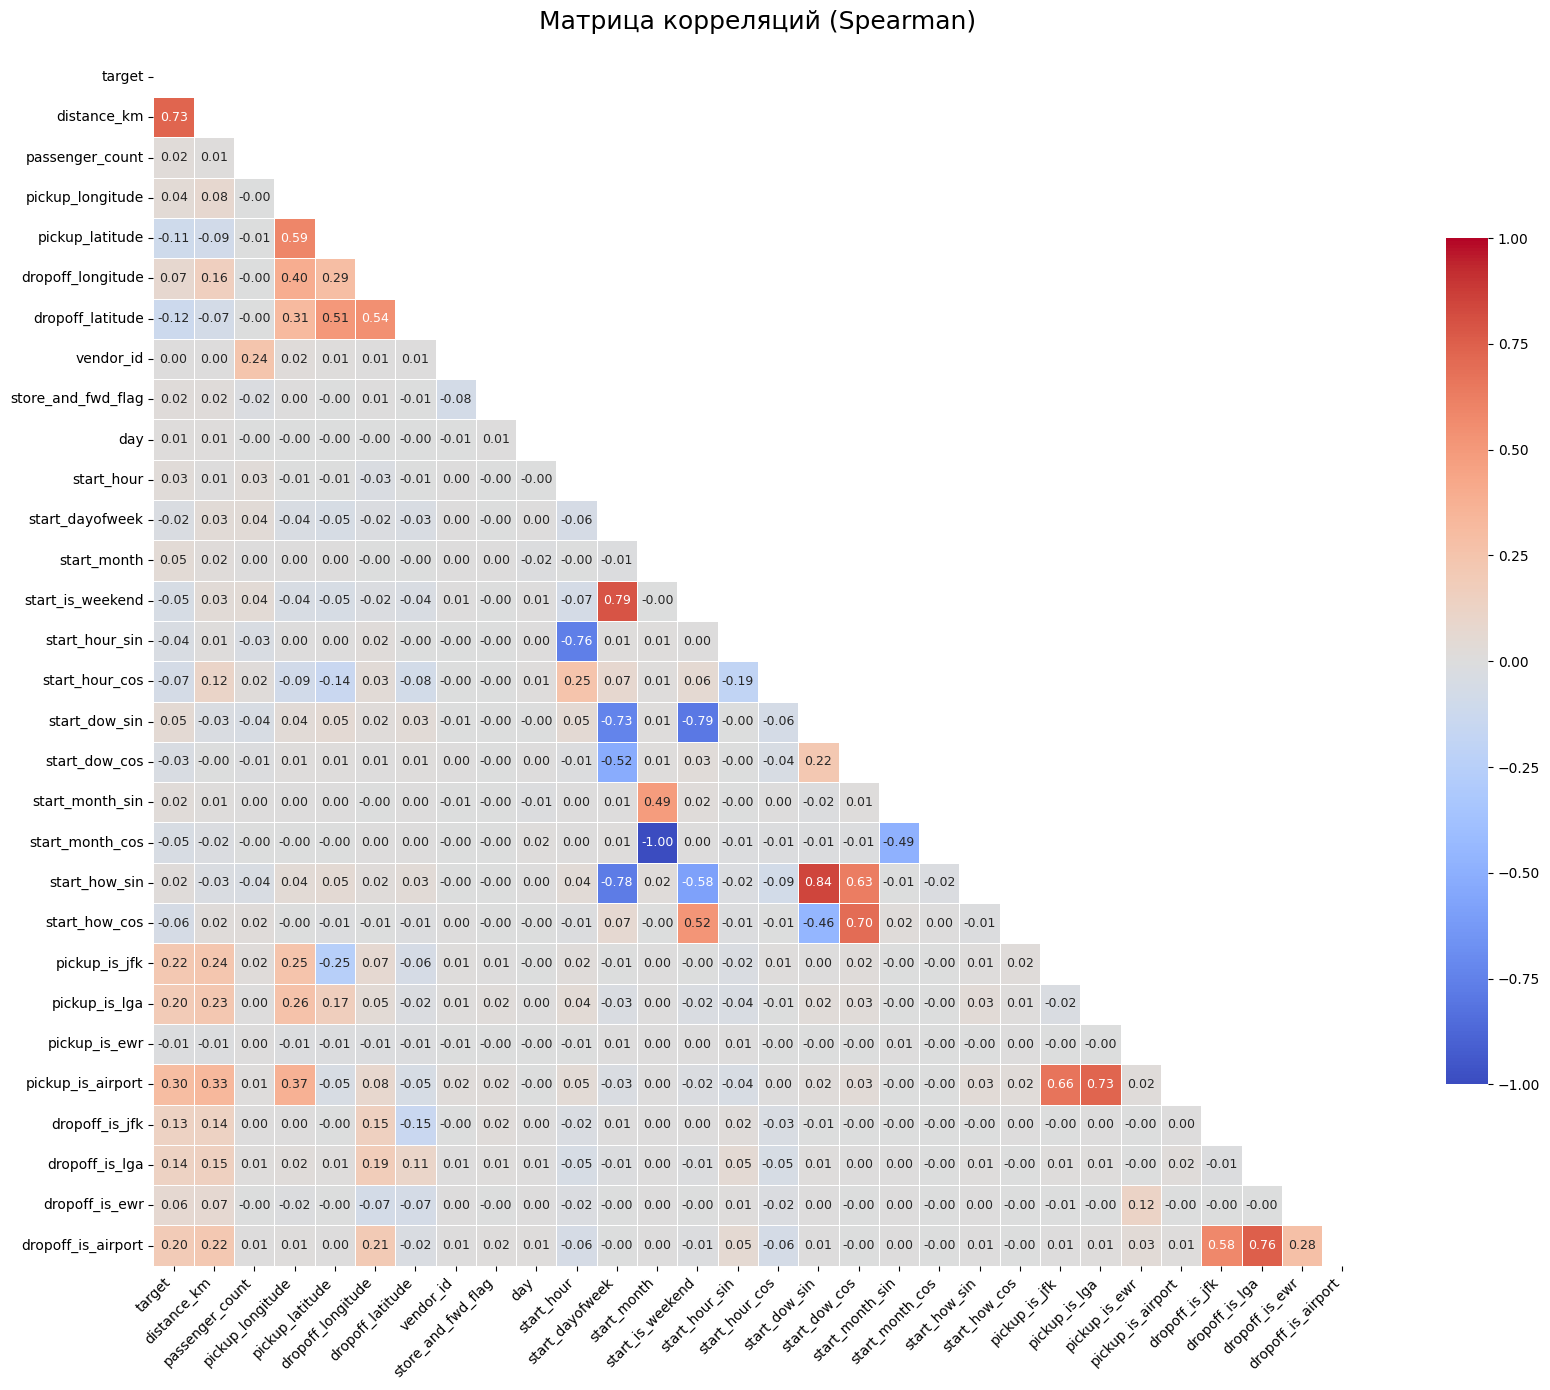

In [15]:
df_corr = train.copy()

cols_to_corr = [
    'target',
    'distance_km',
    'passenger_count',
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'vendor_id', 'store_and_fwd_flag',
    'day', 'start_hour', 'start_dayofweek', 'start_month', 'start_is_weekend',
    'start_hour_sin', 'start_hour_cos',
    'start_dow_sin', 'start_dow_cos',
    'start_month_sin', 'start_month_cos',
    'start_how_sin', 'start_how_cos',
    'pickup_is_jfk', 'pickup_is_lga', 'pickup_is_ewr', 'pickup_is_airport',
    'dropoff_is_jfk', 'dropoff_is_lga', 'dropoff_is_ewr', 'dropoff_is_airport'
]

cols_to_corr = [c for c in cols_to_corr if c in df_corr.columns]

if 'store_and_fwd_flag' in df_corr.columns and df_corr['store_and_fwd_flag'].dtype == 'object':
    df_corr['store_and_fwd_flag'] = df_corr['store_and_fwd_flag'].map({'Y': 1, 'N': 0})

# Считаем корреляцию Спирмена
corr_matrix = df_corr[cols_to_corr].corr(method='spearman')

# Маска
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Рисуем
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .7},
    annot_kws={"size": 9}
)

plt.title('Матрица корреляций (Spearman)', fontsize=18, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

1. **Связь с таргетом (target)**:
  - distance_km (0.73) — главный признак, имеет сильную монотонную связь с целевой переменной.
  - Флаги аэропортов (~0.2–0.3) — имеют умеренную связь. Это значит, что аэропорты — это отдельная специфическая группа поездок.
  - Остальные признаки показывают значения около нуля.

2. **Почему временные признаки (час, месяц) показывают 0?**

  - Корреляция Спирмена измеряет линейную (монотонную) связь. Время суток влияет на поездки нелинейно (например, в 8 утра спрос высокий, в 12 дня — средний, в 3 ночи — низкий). График образует «волну», поэтому коэффициент корреляции близок к нулю.

3. **Красные/синие блоки между признаками:**

  - Это мультиколлинеарность. Она означает, что признаки дублируют информацию друг друга (например, is_jfk является частным случаем is_airport, а start_hour_sin и start_hour_cos описывают одно и то же время). (Их удалим для всех моделей кроме деревянных)


  Плюс, далее не берем признак year так как он везде равен 2016

## 2. Построение baseline-моделей

In [16]:
# подготовим данные к постоению моделей

# для линейных моделей и knn
# Создаем логарифмированное расстояние (так как оно имеет сильный хвост)
for df in (train, public, private):
    df['distance_km_log'] = np.log1p(df['distance_km'])

# 2. Отбираем признаки (убираем сырые часы/дни, оставляем только sin/cos и общие флаги аэропортов)
features_linear = [
    'passenger_count',
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'distance_km_log',        # Логарифм расстояния

    # Время: оставляем только независимые sin/cos для часа и дня недели
    'start_hour_sin', 'start_hour_cos',
    'start_dow_sin', 'start_dow_cos',

    # Убрали: start_how_sin, start_how_cos (дублируют час и день)
    # Убрали: start_is_weekend (дублирует день недели)
    # Убрали: start_month_sin, start_month_cos (имеют корреляцию -1.00)

    # Аэропорты: только общие флаги, без конкретных JFK/LGA/EWR
    'pickup_is_airport', 'dropoff_is_airport',

]

X_train_lin = train[features_linear]
y_train_lin = train['target']

X_val_lin = public[features_linear]
y_val_lin = public['target']

X_test_lin = private[features_linear]

print('Выборки для линейных моделей')
print(f'X_train: {X_train_lin.shape}')
print(f'X_val: {X_val_lin.shape}')
print(f'X_test: {X_test_lin.shape}')

Выборки для линейных моделей
X_train: (79426, 12)
X_val: (15000, 12)
X_test: (25000, 12)


- **StratifiedKFold (5 фолдов)**: Поскольку классы сильно несбалансированы (класс 1 доминирует, класс 3 в меньшинстве), использование обычного KFold могло бы привести к тому, что в некоторых фолдах редких классов не оказалось бы вовсе. Стратификация гарантирует, что пропорции классов в каждом фолде совпадают с исходным train.

- **Pipeline и StandardScaler**: Масштабирование StandardScaler и PCA встроены в Pipeline. Это исключает утечку данных (data leakage), так как скейлер обучается только на тренировочной части каждого фолда и применяется к валидационной.

- **Метрика**: Основная метрика — macro-F1. В отличие от Accuracy, она не позволяет модели «схалтурить», просто предсказывая самый частый класс. Macro-F1 усредняет F1-меру по всем классам (включая редкие) с одинаковым весом, что критически важно для данной задачи.

In [17]:
# настройка кроссвалидации
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# метрики
scores = {'f1_macro': make_scorer(f1_score, average='macro'),
          'precision': make_scorer(precision_score, average='macro'),
          'recall': make_scorer(recall_score, average='macro'),
          'accuracy': 'accuracy'}

# инициализация моделей
# DummyClassifier со случайным угадыванием с учетом частот классов
dummy_model = DummyClassifier(strategy='prior', random_state=42)

# LogisticRegression
lgr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression( max_iter=1000, class_weight='balanced', random_state=42))   #multi_class='multinomial'
])

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=10)),     # берем 10 главных компонент - ускоряем работу
    ('clf', KNeighborsClassifier(n_neighbors=25, weights='distance', n_jobs=-1))
])

# бустинги

models = {
    'Dummy': dummy_model,
    'LogisticRegression': lgr_pipeline,
    'KNN': knn_pipeline
}

results_lin = {}
# кроссвалидация
for name, model in models.items():
  print(f'Запуск CV для модели {name}')
  cv_res = cross_validate(model, X_train_lin, y_train_lin, cv=skf, scoring=scores, n_jobs=-1)
  results_lin[name] = cv_res

  f1_mean = cv_res['test_f1_macro'].mean()
  f1_std = cv_res['test_f1_macro'].std()
  print(f"{name}: Macro-F1 = {f1_mean:.4f} ± {f1_std:.4f}\n")

Запуск CV для модели Dummy
Dummy: Macro-F1 = 0.1702 ± 0.0000

Запуск CV для модели LogisticRegression
LogisticRegression: Macro-F1 = 0.6217 ± 0.0040

Запуск CV для модели KNN
KNN: Macro-F1 = 0.6300 ± 0.0047



## 3. Настройка моделей (подбор гиперпараметров)

### 3.1 Настройка Логистической Регрессии

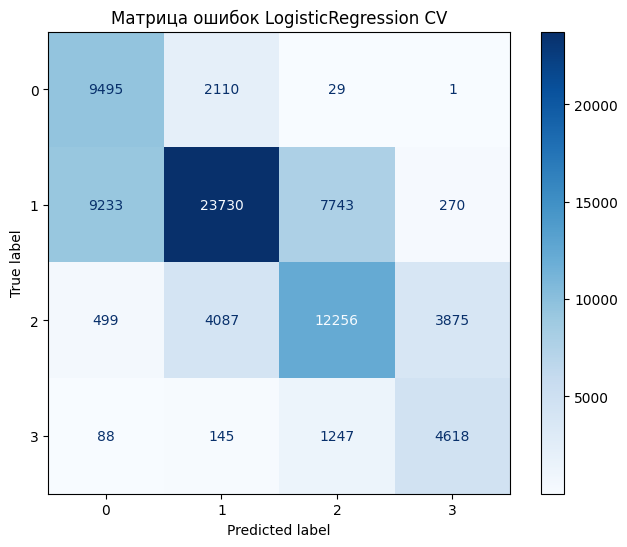

In [18]:
# посмотрим на матрицу ошибок
y_pred_lgr = cross_val_predict(lgr_pipeline, X_train_lin, y_train_lin, cv=skf, n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_pred=y_pred_lgr, y_true=y_train_lin, cmap='Blues', ax=ax)
plt.title('Матрица ошибок LogisticRegression CV')
plt.show()

In [19]:
# GridSearch для логистической регрессии, подбираем силу регуляризации
param_grid_lr = {
    'clf__C': [0.01, 0.1, 1.0, 10.0, 50, 100]
}

grid_lr = GridSearchCV(
    estimator=lgr_pipeline,       # пайплайн логистической регрессии: StandarScaler + LogisticRegression
    param_grid=param_grid_lr,
    cv=skf,                       # Тот же StratifiedKFold
    scoring='f1_macro',
    n_jobs=-1,                    # задействуем все ядра
    verbose=2                     # печатаем процесс в консоль
)

print('Подбор гиперпараметров для LogisticRegression')
grid_lr.fit(X_train_lin, y_train_lin)

print(f"Лучшие параметры: {grid_lr.best_params_}")
print(f"Лучший Macro-F1: {grid_lr.best_score_:.4f}")

Подбор гиперпараметров для LogisticRegression
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Лучшие параметры: {'clf__C': 10.0}
Лучший Macro-F1: 0.6218


- **Лучшие параметры**: C=10.0, solver='lbfgs', class_weight='balanced'.
- **Результат**: Macro-F1 = 0.6218 (по 5-фолдовой кросс-валидации на train).

**Вывод**: Дальнейшее увеличение C (до 50–100) дает прирост лишь в пределах математического шума (~0.001). Модель достигла своего «потолка», оптимально используя созданные признаки (логарифм расстояния и циклическое время).

### 3.2 Подбор гиперпараметров для KNN

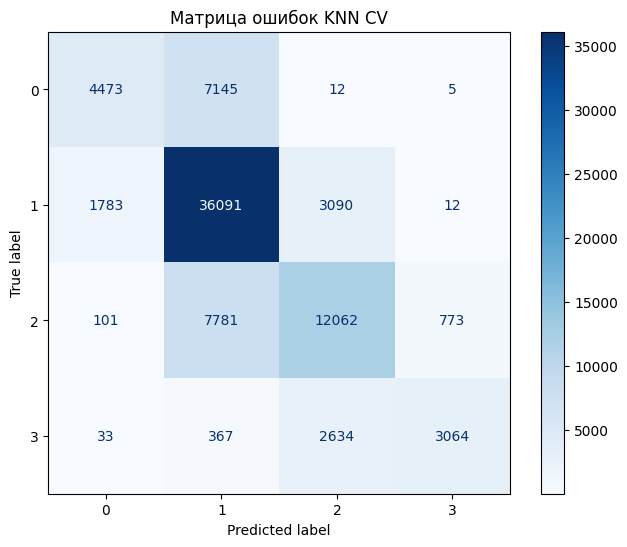

In [20]:
# матрица ошибок для KNN
y_pred_knn = cross_val_predict(knn_pipeline, X_train_lin, y_train_lin, cv=skf, n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_pred=y_pred_knn, y_true=y_train_lin, cmap='Blues', ax=ax)
plt.title('Матрица ошибок KNN CV')
plt.show()

In [21]:
# так как KNN на 80 000 объектов с 5-фолдовой кросс-валидацией и полным перебором параметров, используем RandomSearchCV
param_grid_knn = {
    'clf__n_neighbors': randint(10, 50),
    'clf__weights': ['uniform', 'distance'],
    'clf__p': [1, 2]                            # p=1 (Манхэттенское расстояние), p=2 (Евклидово)
}

random_knn = RandomizedSearchCV(
    estimator=knn_pipeline,
    param_distributions=param_grid_knn,
    n_iter=10,
    cv=skf,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2,
    random_state=42
)

print('Подбор гиперпараметров для KNN')
random_knn.fit(X_train_lin, y_train_lin)

print(f"Лучшие параметры: {random_knn.best_params_}")
print(f"Лучший Macro-F1: {random_knn.best_score_:.4f}")

Подбор гиперпараметров для KNN
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Лучшие параметры: {'clf__n_neighbors': 11, 'clf__p': 2, 'clf__weights': 'distance'}
Лучший Macro-F1: 0.6391


In [22]:
# обновляем параметры на обоих моделях
lgr_pipeline.set_params(**grid_lr.best_params_)
lgr_pipeline.fit(X_train_lin, y_train_lin)

results_lin['LogisticRegression'] = cross_validate(
    lgr_pipeline,
    X_train_lin,
    y_train_lin,
    cv=skf,
    scoring=scores,
    n_jobs=-1
)

# Для KNN
knn_pipeline.set_params(**random_knn.best_params_)
knn_pipeline.fit(X_train_lin, y_train_lin)

results_lin['KNN'] = cross_validate(
    knn_pipeline,
    X_train_lin,
    y_train_lin,
    cv=skf,
    scoring=scores,
    n_jobs=-1
)

## 4. Feature engineering: собственные гипотезы
> В этом разделе мы проверим две гипотезы о новых признаках. Для чистоты эксперимента во всех сравнениях мы используем один и тот же алгоритм с одинаковыми гиперпараметрами и одинаковые CV-разбиения (StratifiedKFold, random_state=42), изменяя только набор признаков.

### 4.1 Гипотеза 1: Манхэттенское расстояние лучше отражает реальный путь в Нью-Йорке
**Идея**: На EDA-карте видно, что город имеет строгую сетчатую структуру улиц. Прямая линия (Haversine) не учитывает, что таксисту приходится ехать по сетке.

**Что меняем**: Добавляем manhattan_km (сумма разниц по широте и долготе) и его логарифм.

**Почему это может помочь**: KNN использует расстояния между объектами. Если мы дадим ему более точное представление о длине пути, он лучше разделит короткие и длинные поездки.

### 4.2 Гипотеза 2: Влияние расстояния на длительность зависит от времени суток

**Идея**: Поездка на 10 км в 3 часа ночи занимает 15 минут, а в 6 вечера (час пик) — 45 минут. Логистическая регрессия — линейная модель, она не может сама «понять», что вес признака distance_km должен меняться в зависимости от часа.

**Что меняем**: Добавляем взаимодействия distance_km_log * start_hour_sin и distance_km_log * start_hour_cos.

**Почему это может помочь**: Это даст линейной модели нелинейность, позволив ей учитывать пробки.

-----------------Результаты для модели LogisticRegression------------------
Запуск CV для Исходные признаки
Запуск CV для Гипотеза 1 + манхэттен
Запуск CV для Гипотеза 2 + взаимодействия


,Вариант признаков,Macro-F1,SD по фолдам
0,Исходные признаки,0.6218,0.0041
1,Гипотеза 1 + манхэттен,0.5815,0.0029
2,Гипотеза 2 + взаимодействия,0.6220,0.0034


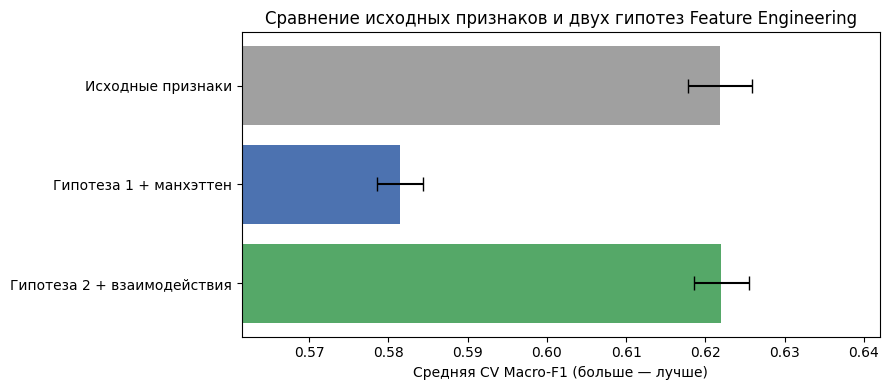

-----------------Результаты для модели KNN------------------
Запуск CV для Исходные признаки
Запуск CV для Гипотеза 1 + манхэттен
Запуск CV для Гипотеза 2 + взаимодействия


,Вариант признаков,Macro-F1,SD по фолдам
0,Исходные признаки,0.6391,0.0049
1,Гипотеза 1 + манхэттен,0.6082,0.0065
2,Гипотеза 2 + взаимодействия,0.6415,0.0059


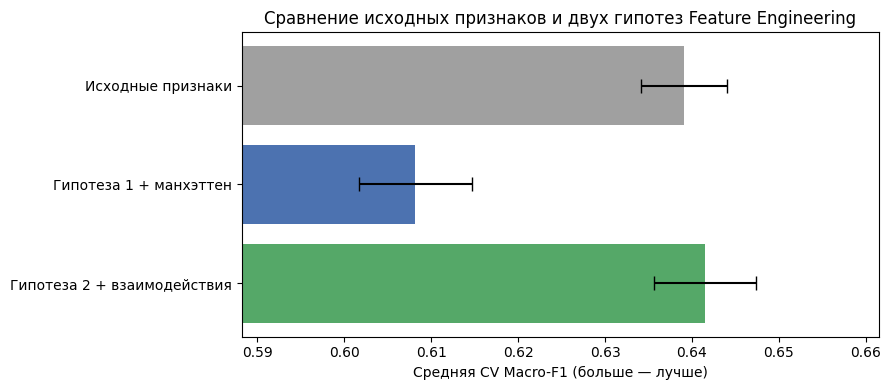

In [47]:
def add_manhattan(df):
    df = df.copy()
    lat_diff = np.abs(df['pickup_latitude'] - df['dropoff_latitude'])
    lon_diff = np.abs(df['pickup_longitude'] - df['dropoff_longitude']) * np.cos(np.radians(df['pickup_latitude']))
    manhattan_km = (lat_diff + lon_diff) * 111.0
    df['distance_km_log'] = np.log1p(manhattan_km)
    return df

def add_interaction(df):
  apdate_df = df.copy()
  apdate_df['dist_x_hour_sin'] = apdate_df['distance_km_log'] * apdate_df['start_hour_sin']
  apdate_df['dist_x_hour_cos'] = apdate_df['distance_km_log'] * apdate_df['start_hour_cos']
  return apdate_df

X_train_base = X_train_lin.copy()
X_train_h1 = add_manhattan(X_train_base)
X_train_h2 = add_interaction(X_train_base)

models = {'LogisticRegression':lgr_pipeline,
          'KNN': knn_pipeline}

for model, model_to_use in models.items():
  print(f'-----------------Результаты для модели {model}------------------')
  variants = {'Исходные признаки': X_train_base,
           'Гипотеза 1 + манхэттен': X_train_h1,
           'Гипотеза 2 + взаимодействия': X_train_h2}

  results_h1_h2 = []
  for name, x_data in variants.items():
    print(f'Запуск CV для {name}')
    fold_f1 = cross_val_score(model_to_use, x_data, y_train_lin, cv=skf, scoring='f1_macro', n_jobs=-1)

    results_h1_h2.append({
        'Вариант признаков': name,
        'Macro-F1': fold_f1.mean(),
        'SD по фолдам': fold_f1.std()
   })

  results_df = pd.DataFrame(results_h1_h2)
  display(results_df.round(4))

  fig, ax = plt.subplots(figsize=(9, 4))
  colors = ['#a0a0a0', '#4c72b0', '#55a868']

  bars = ax.barh(
      results_df["Вариант признаков"],
      results_df["Macro-F1"],
      color=colors,
      xerr=results_df["SD по фолдам"], # Добавляем погрешность (std)
      capsize=5
  )

  ax.invert_yaxis()
  ax.set(
      xlabel="Средняя CV Macro-F1 (больше — лучше)",
      title="Сравнение исходных признаков и двух гипотез Feature Engineering"
  )
  ax.set_xlim(results_df["Macro-F1"].min() - 0.02, results_df["Macro-F1"].max() + 0.02)
  plt.tight_layout()
  plt.show()

В итоге эксперемента, получаем что **манхэттанское растояние ухудшает**, хоть и не значительно, модель.   
Показатель взаимодейтсвия, наоборот, принес прирост в метрике, причем довольно значительный.

In [24]:
# Обновляем все три выборки (train, public, private)
X_train_final = add_interaction(X_train_lin)
X_val_final = add_interaction(X_val_lin)
X_test_final = add_interaction(X_test_lin)

lgr_final = clone(lgr_pipeline).set_params(**grid_lr.best_params_)
knn_final = clone(knn_pipeline).set_params(**random_knn.best_params_)

## 5. Выбор итоговой модели
> Будем выбирать среди LogisticRegression и KNN с наилучшими подобранными гиперпараметрами и добавленными взаимодействиями

Генерируем финальные предсказания для LogReg...
Генерируем финальные предсказания для KNN...

--- Финальный Classification Report: Logistic Regression ---
              precision    recall  f1-score   support

           0     0.4905    0.8164    0.6129     11635
           1     0.7899    0.5791    0.6683     40976
           2     0.5781    0.5939    0.5859     20717
           3     0.5272    0.7557    0.6211      6098

    accuracy                         0.6313     79426
   macro avg     0.5965    0.6863    0.6220     79426
weighted avg     0.6707    0.6313    0.6351     79426


--- Финальный Classification Report: KNN ---
              precision    recall  f1-score   support

           0     0.6480    0.4602    0.5382     11635
           1     0.7120    0.8429    0.7720     40976
           2     0.6657    0.5967    0.6293     20717
           3     0.7819    0.5231    0.6268      6098

    accuracy                         0.6981     79426
   macro avg     0.7019    0.6058    0

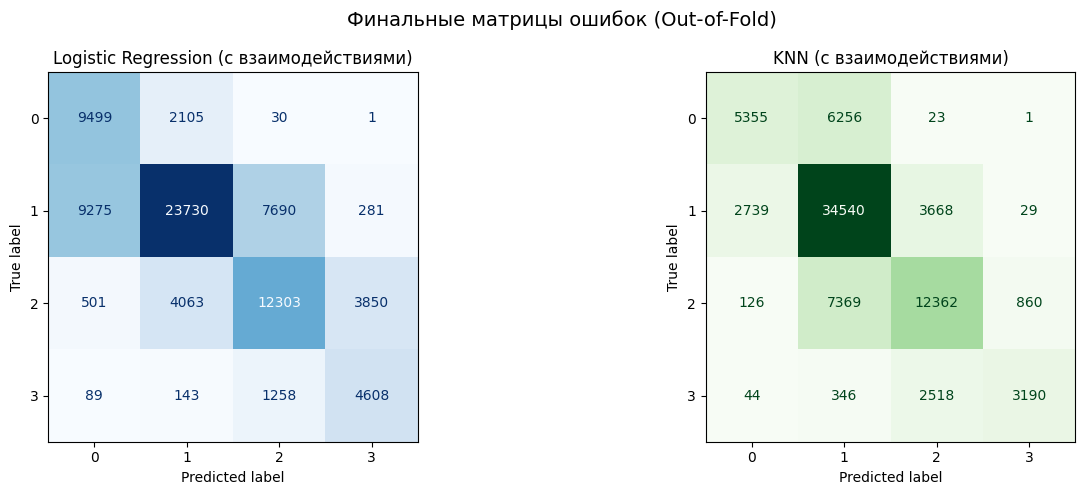

In [25]:
# Получаем честные out-of-fold предсказания на обновленных данных
print("Генерируем финальные предсказания для LogReg...")
y_pred_lr_final = cross_val_predict(lgr_final, X_train_final, y_train_lin, cv=skf, n_jobs=-1)

print("Генерируем финальные предсказания для KNN...")
y_pred_knn_final = cross_val_predict(knn_final, X_train_final, y_train_lin, cv=skf, n_jobs=-1)

# Выводим отчеты по классам
print("\n--- Финальный Classification Report: Logistic Regression ---")
print(classification_report(y_train_lin, y_pred_lr_final, digits=4))

print("\n--- Финальный Classification Report: KNN ---")
print(classification_report(y_train_lin, y_pred_knn_final, digits=4))

# Строим финальные матрицы ошибок
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train_lin, y_pred_lr_final, cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Logistic Regression (с взаимодействиями)')

ConfusionMatrixDisplay.from_predictions(
    y_train_lin, y_pred_knn_final, cmap='Greens', ax=axes[1], colorbar=False
)
axes[1].set_title('KNN (с взаимодействиями)')

plt.suptitle('Финальные матрицы ошибок (Out-of-Fold)', fontsize=14)
plt.tight_layout()
plt.show()

**Итоговый лидер (среди не амсамблевых моделей) — KNN (Macro-F1 = 0.6416)**:
KNN значительно превосходит логистическую регрессию как по Macro-F1 (+0.02), так и по Accuracy (+0.067). Это говорит о том, что для данной задачи локальные закономерности (похожие поездки) работают лучше, чем глобальные линейные границы.

**Анализ поведения KNN**
KNN ведет себя гораздо более сбалансированно благодаря локальной природе алгоритма.

  - Класс 3 (>30 мин): KNN показывает Precision = 0.78 (когда он предсказывает долгую поездку, он почти всегда прав), но Recall = 0.52. Модель «боится» ошибиться и предсказывает класс 3 только при очень явном совпадении признаков.

  - Класс 1 (5–15 мин): KNN отлично справляется с большинством (Recall = 0.84, F1 = 0.77).

  - Класс 0 (<5 мин): Самый проблемный класс для KNN. Recall упал до 0.46. Алгоритм часто путает короткие поездки с классом 1.


> Основная проблема обеих моделей — ошибки на границах классов (0↔1 и 2↔3).




## 6. Бустинг

In [28]:
# Признаки для бустингов
features_boost = [
    # Числовые/координаты
    'passenger_count', 'vendor_id',
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'distance_km',                    # сырое, без логарифма
    'manhattan_km',                   # добавим, т.к. отражает сетку улиц

    # Время (сырые категории — деревьям так проще)
    'start_hour', 'start_dayofweek', 'start_month', 'start_is_weekend',

    # Аэропорты (все флаги)
    'pickup_is_jfk', 'pickup_is_lga', 'pickup_is_ewr', 'pickup_is_airport',
    'dropoff_is_jfk', 'dropoff_is_lga', 'dropoff_is_ewr', 'dropoff_is_airport',

    # Явные взаимодействия (деревьям тоже помогают)
    'dist_x_hour_sin', 'dist_x_hour_cos',
]

In [31]:
# Добавляем manhattan_km в public/private
def add_manhattan_full(df):
    df = df.copy()
    lat_diff = np.abs(df['pickup_latitude'] - df['dropoff_latitude'])
    lon_diff = np.abs(df['pickup_longitude'] - df['dropoff_longitude']) * np.cos(np.radians(df['pickup_latitude']))
    df['manhattan_km'] = (lat_diff + lon_diff) * 111.0
    return df

# Применяем ко всем
for df in (train, public, private):
    # Взаимодействия (уже нужны для всех)
    if 'dist_x_hour_sin' not in df.columns:
        df['dist_x_hour_sin'] = df['distance_km_log'] * df['start_hour_sin']
        df['dist_x_hour_cos'] = df['distance_km_log'] * df['start_hour_cos']

    # Проще все за раз:
    df['manhattan_km'] = (np.abs(df['pickup_latitude'] - df['dropoff_latitude']) +
                          np.abs(df['pickup_longitude'] - df['dropoff_longitude']) * np.cos(np.radians(df['pickup_latitude']))) * 111.0

X_train_boost = train[features_boost]
y_train_boost = train['target']
X_val_boost = public[features_boost]
y_val_boost = public['target']
X_test_boost = private[features_boost]

print(f"X_train_boost: {X_train_boost.shape}")

X_train_boost: (79426, 22)


### Обучение моделей бустинга

In [35]:
# словарь метрик
scores = {'f1_macro': make_scorer(f1_score, average='macro'),
          'accuracy': 'accuracy'}

# 1. LightGBM (самый быстрый)
lgb_model = lgb.LGBMClassifier(
    objective='multiclass', num_class=4,
    n_estimators=500, learning_rate=0.05, num_leaves=31,
    class_weight='balanced',
    random_state=42, n_jobs=-1, verbose=-1
)

# 2. XGBoost
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob', num_class=4,
    n_estimators=500, learning_rate=0.05, max_depth=6,
    random_state=42, n_jobs=-1, tree_method='hist'
)

# 3. CatBoost (самый точный, но медленный)
cat_model = CatBoostClassifier(
    loss_function='MultiClass',
    iterations=500, learning_rate=0.05, depth=6,
    auto_class_weights='Balanced',   # аналог class_weight='balanced'
    random_seed=42, verbose=0, thread_count=-1
)

boost_models = {
    'LightGBM': lgb_model,
    'XGBoost': xgb_model,
    'CatBoost': cat_model
}

results_boost = {}
for name, model in boost_models.items():
    print(f"\n>>> Запуск CV для {name}...")
    res = cross_validate(model, X_train_boost, y_train_boost,
                         cv=skf, scoring=scores, n_jobs=-1, verbose=1)
    results_boost[name] = res
    print(f"{name}: Macro-F1 = {res['test_f1_macro'].mean():.4f} ± {res['test_f1_macro'].std():.4f}")


>>> Запуск CV для LightGBM...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:  3.8min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


LightGBM: Macro-F1 = 0.6996 ± 0.0050

>>> Запуск CV для XGBoost...


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:  1.7min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


XGBoost: Macro-F1 = 0.7104 ± 0.0041

>>> Запуск CV для CatBoost...
CatBoost: Macro-F1 = 0.6760 ± 0.0032


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:  2.1min finished


In [38]:
# сделаем подбор гиперпараметров для XGBoost
# 1. Задаем сетку параметров для XGBoost
param_dist_xgb = {
    'max_depth': randint(4, 12),                 # Глубина деревьев (от 4 до 12)
    'learning_rate': uniform(0.01, 0.1),         # Скорость обучения (0.01 - 0.11)
    'n_estimators': randint(300, 1000),          # Количество деревьев
    'subsample': uniform(0.7, 0.3),              # Доля объектов для каждого дерева
    'colsample_bytree': uniform(0.7, 0.3),       # Доля признаков для каждого дерева
    'min_child_weight': randint(1, 10),          # Защита от переобучения
    'gamma': uniform(0, 1)                       # Минимальный выигрыш для разбиения
}

# 2. Инициализируем базовую модель
xgb_base = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

# 3. Запускаем RandomizedSearchCV
search_xgb = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist_xgb,
    n_iter=15,                # Проверим 15 случайных комбинаций (хватит для хорошего результата)
    cv=skf,                   # Наши 5 фолдов
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2,
    random_state=42
)

print("Начинаем подбор гиперпараметров для XGBoost...")
search_xgb.fit(X_train_boost, y_train_boost)

print("\n=== ЛУЧШИЕ ПАРАМЕТРЫ ===")
print(search_xgb.best_params_)
print(f"Лучший Macro-F1: {search_xgb.best_score_:.4f}")

# Сохраняем лучшую модель
best_boost_model = search_xgb.best_estimator_

Начинаем подбор гиперпараметров для XGBoost...
Fitting 5 folds for each of 15 candidates, totalling 75 fits

=== ЛУЧШИЕ ПАРАМЕТРЫ ===
{'colsample_bytree': np.float64(0.9049790556476374), 'gamma': np.float64(0.6099966577826209), 'learning_rate': np.float64(0.09331949117361643), 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 861, 'subsample': np.float64(0.8987566853061946)}
Лучший Macro-F1: 0.7172


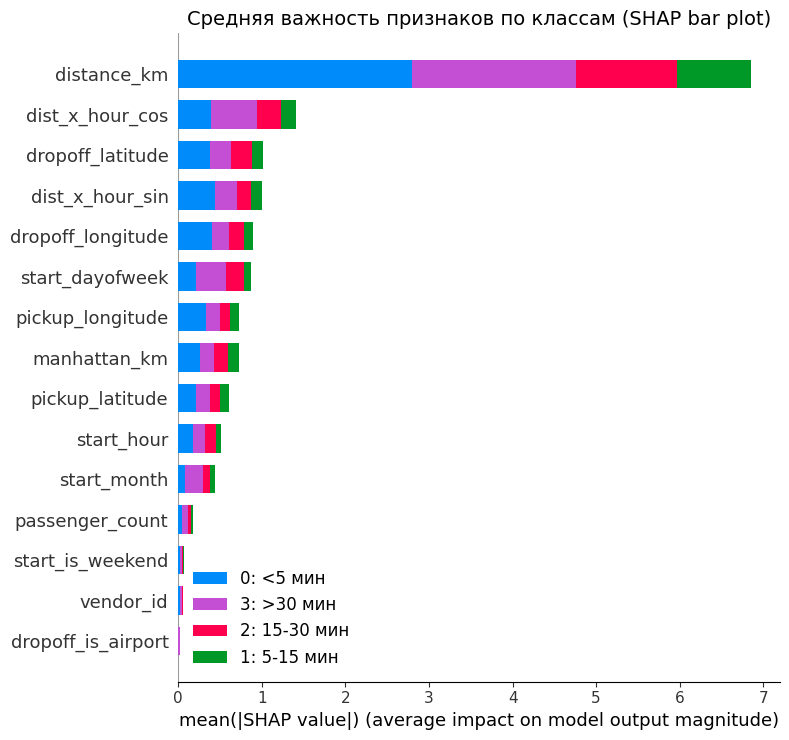

In [45]:
# интерпретируем результаты модели с помощью shap
import shap

class_names = ['0: <5 мин', '1: 5-15 мин', '2: 15-30 мин', '3: >30 мин']

# 2. Строим summary_plot с типом "bar"
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values,           # Наши посчитанные SHAP-значения (3D массив)
    X_sample,              # Выборка признаков (500 объектов)
    plot_type="bar",       # Тип графика: столбчатая диаграмма
    class_names=class_names,
    max_display=15,        # Показываем топ-15 признаков
    show=False             # Отключаем авто-показ, чтобы добавить title
)

plt.title('Средняя важность признаков по классам (SHAP bar plot)', fontsize=14)
plt.tight_layout()
plt.show()

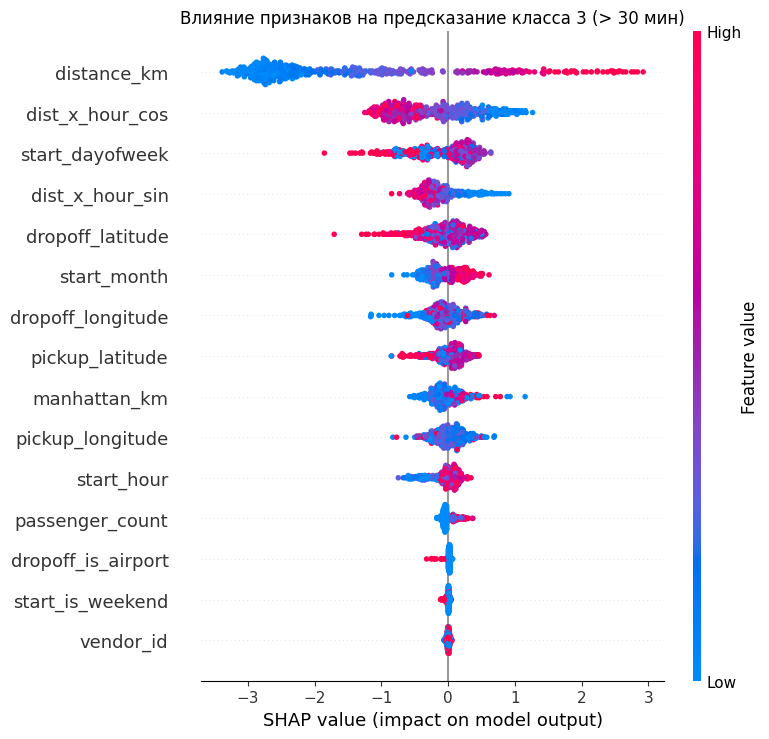

In [46]:
# интерпретируем результаты модели с помощью shap (только класс 3)

# 1. Считаем shap_values
explainer = shap.TreeExplainer(best_boost_model)
X_sample = X_train_boost.sample(500, random_state=42)
shap_values = explainer.shap_values(X_sample)

# 2. Универсальный хелпер для извлечения класса
def get_shap_for_class(shap_vals, class_idx):
    if isinstance(shap_vals, list):
        return shap_vals[class_idx]          # Старый формат (список)
    elif shap_vals.ndim == 3:
        return shap_vals[:, :, class_idx]    # Новый формат (samples, features, classes)
    else:
        return shap_vals                     # Уже 2D (бинарый)

# 3. Строим beeswarm для класса 3 (долгие поездки)
plt.figure(figsize=(10, 8))
shap.summary_plot(
    get_shap_for_class(shap_values, 3),
    X_sample,
    show=False,
    max_display=15
)
plt.title('Влияние признаков на предсказание класса 3 (> 30 мин)')
plt.tight_layout()
plt.show()

## 7. Выводы

Обучение финального XGBoost на полном train...
Генерация предсказаний для test-public...

--- Оценка XGBoost на test-public ---
Macro-F1: 0.7139
Accuracy: 0.7523

--- Classification Report: XGBoost (test-public) ---
              precision    recall  f1-score   support

           0     0.7112    0.6083    0.6557      2267
           1     0.7733    0.8469    0.8084      7683
           2     0.7154    0.6950    0.7051      3885
           3     0.8016    0.6000    0.6863      1165

    accuracy                         0.7523     15000
   macro avg     0.7504    0.6876    0.7139     15000
weighted avg     0.7511    0.7523    0.7491     15000



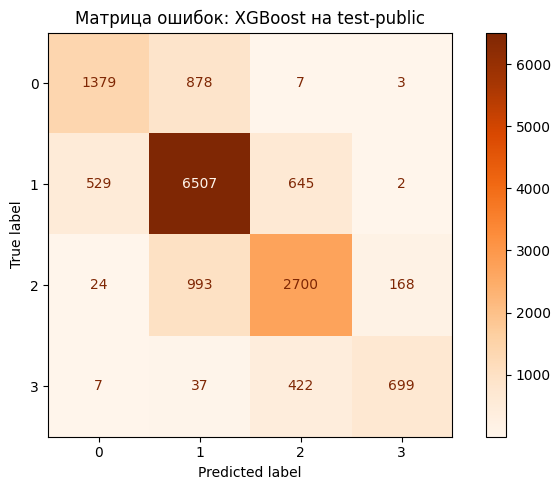

In [43]:
# 1. Обучаем лучшую модель на всем тренировочном наборе
print("Обучение финального XGBoost на полном train...")
best_boost_model.fit(X_train_boost, y_train_boost)

# 2. Делаем предсказания на test-public
print("Генерация предсказаний для test-public...")
y_pred_boost_public = best_boost_model.predict(X_val_boost)

# 3. Выводим метрики
print("\n--- Оценка XGBoost на test-public ---")
print(f"Macro-F1: {f1_score(y_val_boost, y_pred_boost_public, average='macro'):.4f}")
print(f"Accuracy: {accuracy_score(y_val_boost, y_pred_boost_public):.4f}")

print("\n--- Classification Report: XGBoost (test-public) ---")
print(classification_report(y_val_boost, y_pred_boost_public, digits=4))

# 4. Строим матрицу ошибок
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val_boost,
    y_pred_boost_public,
    cmap='Oranges',
    ax=ax
)
ax.set_title('Матрица ошибок: XGBoost на test-public')
plt.tight_layout()
plt.show()

In [44]:
# делаем предсказания на финальной выборке
# 1. Делаем предсказания для test-private на лучшей модели
print("Генерация предсказаний для test-private (XGBoost)...")
predictions_boost = best_boost_model.predict(X_test_boost)

# 2. Формируем DataFrame
submission_boost = pd.DataFrame({
    'trip_id': private['trip_id'],
    'prediction': predictions_boost
})

# 3. Проверки
print(f"\nРазмер сабмита: {submission_boost.shape}")
print(f"Уникальные классы: {sorted(submission_boost['prediction'].unique())}")
print("\nРаспределение классов в новом сабмите:")
print(submission_boost['prediction'].value_counts(normalize=True).round(4).sort_index())

# 4. Сохраняем
submission_boost.to_csv('submission_xgboost.csv', index=False)

Генерация предсказаний для test-private (XGBoost)...

Размер сабмита: (25000, 2)
Уникальные классы: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Распределение классов в новом сабмите:
prediction
0    0.1306
1    0.5620
2    0.2500
3    0.0574
Name: proportion, dtype: float64


### Сравнение моделей и финальный выбор
В ходе работы было протестировано несколько классов алгоритмов. Результаты финальной кросс-валидации (5-fold, Macro-F1):

- DummyClassifier: **~0.17** (базовая точка отсчета)

- Logistic Regression: **~0.62** (линейная модель)

- KNN: **0.6416** (метрическая модель, локальные зависимости)

- XGBoost (базовый): **0.7104**

- XGBoost (с подобранными гиперпараметрами): **0.7172**

Финальная конфигурация: Для итогового сабмита выбран XGBoost с параметрами: max_depth=6, learning_rate=0.093, n_estimators=861, subsample=0.9, colsample_bytree=0.9, gamma=0.61.

### Почему именно XGBoost?
Базовые модели (LogReg и KNN) достигли своего «потолка» на уровне 0.64. Логистическая регрессия не может уловить сложные нелинейные взаимодействия, а KNN страдает от «проклятия размерности» и дисбаланса классов. Градиентный бустинг блестяще справился с задачей, так как деревья решений автоматически находят нелинейные пороги (например, «если расстояние > 10 км И час пик, то это точно класс 3»).

### Интерпретация модели через SHAP (Влияние на класс 3)
Для понимания логики финальной модели был проведен SHAP-анализ для класса 3 (поездки > 30 минут). График beeswarm (на изображении выше) показывает, как признаки влияют на предсказание:

- distance_km (Абсолютный лидер): Высокие значения (красные точки) сильно смещают предсказание вправо (увеличивают вероятность класса 3). Это самое логичное и сильное правило модели.

- dist_x_hour_cos (Наше Feature Engineering): Признак взаимодействия расстояния и времени оказался вторым по важности! Это доказывает, что наша гипотеза была верной: модель активно использует комбинацию «дистанция × время суток» для определения долгих поездок (например, короткая дистанция в час пик может занять > 30 минут).

- География (dropoff_latitude, pickup_latitude): Модель поняла, что поездки, заканчивающиеся на севере или востоке карты (например, в аэропорты или отдаленные районы), чаще бывают долгими.

- start_dayofweek и start_month: Сезонность и дни недели также вносят вклад (например, в выходные пробки меньше, и поездки короче).

Неважные признаки: passenger_count и vendor_id почти не влияют на предсказание длительности, что подтверждается их нулевым вкладом на графике.


